# Noncommuting thermal filtering with explicit Pauli LCU

Use $H/E_0=0.6Z+0.4X$, chosen $E_0=1$, $k_B=1$, and $\beta=1.25/E_0$ ($T=0.8E_0$). The input is a Bell purification of the maximally mixed system, prepared by H and CX. An imaginary-time Taylor polynomial is built algebraically from Pauli coefficients and loaded into actual PREPARE/SELECT/unprepare circuits.

This original bounded implementation uses no eigenvector or dense matrix as a quantum gate. Pauli aggregation and expanded indexed access can grow exponentially. Scalable word-indexed filtering, oblivious amplitude amplification, certified rotation synthesis and physical estimates remain planned. Qiskit 2.6.2 and SciPy 1.18.1 supply circuit and independent classical validation tools; the chapter gives primary references and exact package credit.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "src/openquantum/simulation/thermal_filter.py").exists() and (root.parent / "src/openquantum/simulation/thermal_filter.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/thermal_filter.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import thermal_filter as tf
else:
    # Download thermal_filter.py and lcu.py beside this notebook.
    sys.path.insert(0, str(root))
    import thermal_filter as tf

terms = tf.DEFAULT_TERMS
beta, degree = 1.25, 6
access = tf.build_thermal_lcu(terms, beta, degree)
print(f"Actual aggregated LCU normalization: {access.normalization:.12f}")
display(pd.DataFrame([{"Pauli": label, "coefficient real": complex(c).real, "coefficient imag": complex(c).imag} for c, label in access.terms]))

Actual aggregated LCU normalization: 1.749667045805


,Pauli,coefficient real,coefficient imag
0,I,1.103293,0.0
1,X,-0.258549,0.0
2,Z,-0.387824,0.0


## Actual coherent circuit and conditional output

The filter is $T_K=\sum_{k=0}^K(-\beta H/2)^k/k!$, with access normalization $s=\sum_j|b_j|$ for aggregated $T_K=\sum_jb_jP_j$. The actual zero-label block is $T_K/s$. Acting on a Bell pair and accepting label zero prepares a conditional purification whose reduced state is $T_KT_K^\dagger/\operatorname{Tr}(T_KT_K^\dagger)$.

Its success probability is $\operatorname{Tr}(T_K^\dagger T_K)/(d s^2)$ for system dimension $d$. The state checks below describe the system before final readout. The complete trial circuits measure labels, reset the reference without conditioning, rotate into the requested Pauli basis and measure the system. Their output is an accepted measured trial.

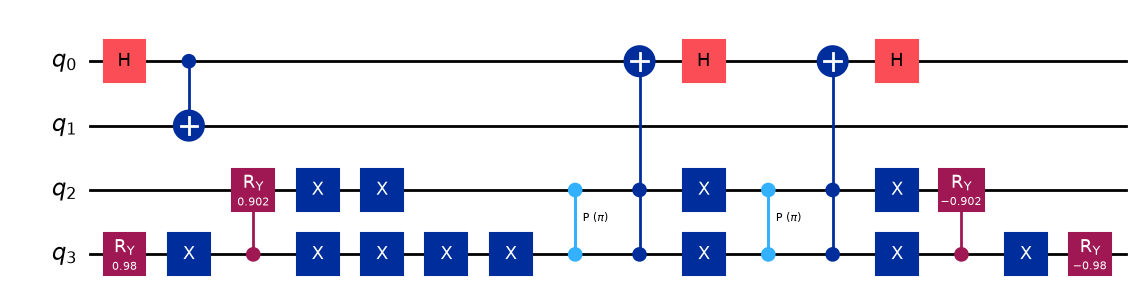

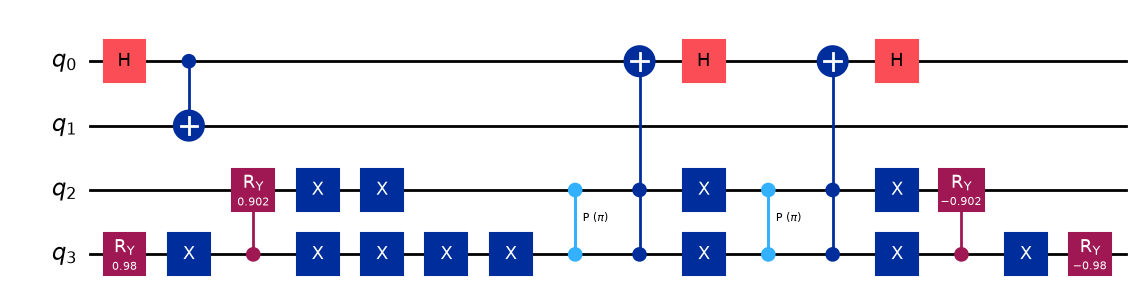

In [2]:
tf.build_thermal_filter(terms, beta, degree).draw(output="mpl", fold=30)

## Independent block, purification, state and observable checks

Every actual access block is compared with an independently evaluated matrix Taylor polynomial. The actual Bell-filter output is checked against that polynomial, and its reduced state against normalized $e^{-\beta H}$. The matrix exponential is only a classical reference. Polynomial error and conditional thermal error are different metrics.

In [3]:
degrees = (0, 1, 2, 4, 6, 8)
betas = (0, .5, 1.25, 2)
checks = [tf.thermal_filter_check(terms, value, order) for value in betas for order in degrees]
rows = [{"beta": c["beta"], "degree": c["degree"], "Gibbs trace distance": c["gibbs_trace_distance"],
         "polynomial operator error": c["polynomial_filter_operator_error"],
         "acceptance": c["acceptance_probability"],
         "energy bias": abs(c["actual_observables"]["energy"]-c["exact_observables"]["energy"])} for c in checks]
default = tf.thermal_filter_check(terms, beta, degree)
assert max(c["actual_access_block_spectral_error"] for c in checks) < 1e-10
assert max(c["actual_reduced_state_error_vs_polynomial"] for c in checks) < 1e-10
assert default["gibbs_trace_distance"] < 1e-6
display(pd.DataFrame([r for r in rows if r["beta"] == beta]))
display(pd.DataFrame({"actual": default["actual_observables"], "exact Gibbs": default["exact_observables"]}))
print(f"Default access-block error: {default['actual_access_block_spectral_error']:.3e}")
print(f"Default conditional Gibbs trace distance: {default['gibbs_trace_distance']:.3e}")

,beta,degree,Gibbs trace distance,polynomial operator error,acceptance,energy bias
0,1.25,0,3.584865e-01,5.694008e-01,1.000000,5.170165e-01
1,1.25,1,1.611625e-02,1.187069e-01,0.455621,2.324319e-02
2,1.25,2,8.013656e-03,1.714442e-02,0.475195,1.155746e-02
3,1.25,4,8.085378e-05,1.673967e-04,0.468656,1.166090e-04
4,1.25,6,3.933638e-07,7.938827e-07,0.468590,5.673173e-07
5,1.25,8,1.114065e-09,2.213675e-09,0.468590,1.606728e-09


,actual,exact Gibbs
energy,-5.170160e-01,-0.517017
X0,-3.977046e-01,-0.397705
Y0,3.394383e-34,0.000000
Z0,-5.965569e-01,-0.596558


Default access-block error: 1.286e-16
Default conditional Gibbs trace distance: 3.934e-07


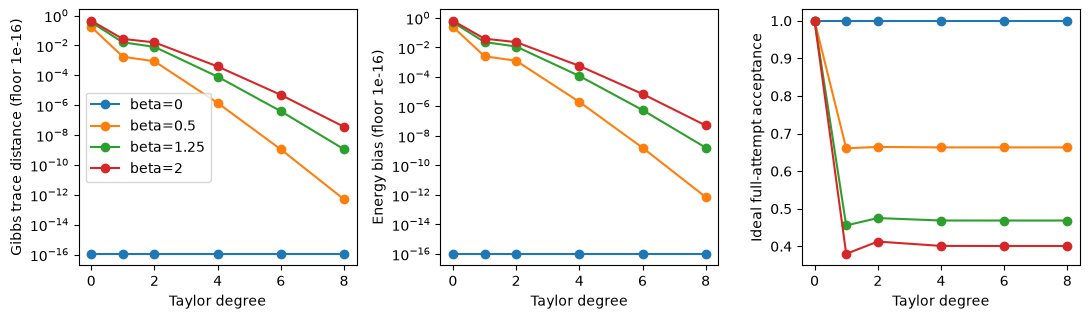

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for value in betas:
    group = [r for r in rows if r["beta"] == value]
    axes[0].semilogy([r["degree"] for r in group], [max(r["Gibbs trace distance"], 1e-16) for r in group], "o-", label=f"beta={value:g}")
    axes[1].semilogy([r["degree"] for r in group], [max(r["energy bias"], 1e-16) for r in group], "o-")
    axes[2].plot([r["degree"] for r in group], [r["acceptance"] for r in group], "o-")
axes[0].set(xlabel="Taylor degree", ylabel="Gibbs trace distance (floor 1e-16)")
axes[1].set(xlabel="Taylor degree", ylabel="Energy bias (floor 1e-16)")
axes[2].set(xlabel="Taylor degree", ylabel="Ideal full-attempt acceptance")
axes[0].legend()
fig.tight_layout()
plt.show()

## Accepted-shot cost and separate error contracts

Because X and Z do not commute, a Z-basis bitstring does not supply the complete energy. Separate accepted X and Z sample means are weighted by 0.4 and 0.6. The workload allocates statistical confidence across both means and acceptance confidence across all required accepted slots. Every capped retry is charged for the full reset/access/readout schedule.

Conditioning amplifies coherent error. A requested operator bound on the coherent Bell-preparation and access unitary would imply a separate conditional trace-distance and mean-bias bound; it is hypothetical until a concrete synthesis certificate exists. The QDK mean-fit scalar is not such a certificate. Ideal retry counts and hypothetical synthesis-adjusted counts are separate. Sampling and physical faults have their own probability budgets; no finite-shot experiment or physical estimate is reported.

In [5]:
circuits = {axis: tf.decompose_thermal_filter(tf.build_thermal_trial(terms, beta, degree, measurement=axis)) for axis in ("X", "Z")}
display(pd.DataFrame({axis: dict(c.count_ops()) for axis, c in circuits.items()}).fillna(0).astype(int))
workload = tf.thermal_energy_workload(default["acceptance_probability"], terms=terms)
synthesis = tf.conditioned_synthesis_bounds(default["acceptance_probability"], 1e-4)
conditional_workload = tf.thermal_energy_workload(synthesis["perturbed_acceptance_lower_bound"], terms=terms)
display(pd.DataFrame(workload["groups"]))
display(pd.DataFrame([{"metric": key, "value": synthesis[key]} for key in ("full_circuit_operator_error_allowance", "conditional_state_trace_distance_bound", "single_pauli_mean_bias_bound", "perturbed_acceptance_lower_bound")]))
print(f"Ideal capped complete trials: {workload['worst_case_complete_trials']:,}")
print(f"Hypothetical synthesis-adjusted capped trials: {conditional_workload['worst_case_complete_trials']:,}")
print("All shot/retry budgets are unexecuted proposals; no certified synthesis or physical confidence.")

,X,Z
cx,21,21
ry,7,7
rz,7,8
t,7,6
x,6,6
tdg,6,6
reset,5,5
h,3,2
measure,3,3


,axis,coefficient,accepted_shots,pauli_statistical_error,statistical_failure,complete_trial_cap_per_accepted_shot,worst_case_complete_trials,expected_complete_trials,expected_complete_trials_uncapped,expected_complete_trials_stopped_at_cap,expected_complete_trials_scope
0,X,0.4,14855,0.03,0.0025,25,371375,31701.47129,31701.47129,31701.466956,legacy alias for uncapped geometric expectatio...
1,Z,0.6,14855,0.03,0.0025,25,371375,31701.47129,31701.47129,31701.466956,legacy alias for uncapped geometric expectatio...


,metric,value
0,full_circuit_operator_error_allowance,0.000100
1,conditional_state_trace_distance_bound,0.000292
2,single_pauli_mean_bias_bound,0.000584
3,perturbed_acceptance_lower_bound,0.468453


Ideal capped complete trials: 742,750
Hypothetical synthesis-adjusted capped trials: 742,750
All shot/retry budgets are unexecuted proposals; no certified synthesis or physical confidence.


## Optional live exploration

Live controls regenerate the actual circuit/reference check with a Python kernel. Static execution omits widget objects and uses the saved results above.

In [6]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(beta=1.25, degree=6):
        check = tf.thermal_filter_check(terms, beta, degree)
        display(pd.DataFrame([{"beta": beta, "degree": degree, "Gibbs trace distance": check["gibbs_trace_distance"], "acceptance": check["acceptance_probability"]}]))
    display(widgets.interactive(explore, beta=widgets.FloatSlider(min=0,max=4,step=.25,value=1.25),
                               degree=widgets.IntSlider(min=0,max=8,value=6)))

## Scope and downloads

The one-qubit artifact example is bounded separately from the reusable Pauli generator. The module limits system width to four, aggregated terms to 256, Taylor degree to 12 and $\beta\sum|c_j|/2$ to 10. Statevector validation stops at 12 total system/reference/label qubits. No dense reference is a quantum gate, and no scalable oracle or amplitude amplification is claimed.

For standalone execution, put `thermal_filter.py` and `lcu.py` beside this notebook and install the project’s pinned Python 3.12 environment. The generated metadata records source hashes, versions, actual access, measurement/reset costs, and classical preprocessing times.